In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
DATASET_PATH = Path("../data/paysim.csv")
if not DATASET_PATH.exists():
    print("Dataset not found!")

In [3]:
df = pd.read_csv(DATASET_PATH)
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Your first task is to answer these questions without using AI to derive the answers:
- How many rows and columns are there?
- Which columns are categorical and which are numerical?
- Are there missing values?
- Are there duplicate rows?
- What does each feature represent?

In [4]:
print(f'Shape of DF\n - Rows: {df.shape[0]}\n - Columns: {df.shape[1]}')
print(f"""Data-types
 - Categorical: {len(df.columns[df.dtypes == "str"])}
 - Numerical: {len(df.columns[df.dtypes != "str"])}
""")
print(f'Missing Values:\n{df.isnull().sum()}\n')
print(f'Duplicated Values: {df.duplicated().sum()}')


Shape of DF
 - Rows: 6362620
 - Columns: 11
Data-types
 - Categorical: 3
 - Numerical: 8

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicated Values: 0


In [5]:
expected_balance = np.where(
    df['type'] == 'CASH_IN',
    df['oldbalanceOrg'] + df['amount'],
    df['oldbalanceOrg'] - df['amount']
)

df['balance_consistent'] = np.isclose(
    expected_balance,
    df['newbalanceOrig'],
    atol=0.01,
    rtol=0
)

In [6]:
df[(~df['balance_consistent']) & (df['isFraud'] == 0)].count()

step                  3779458
type                  3779458
amount                3779458
nameOrig              3779458
oldbalanceOrg         3779458
newbalanceOrig        3779458
nameDest              3779458
oldbalanceDest        3779458
newbalanceDest        3779458
isFraud               3779458
isFlaggedFraud        3779458
balance_consistent    3779458
dtype: int64

In [7]:
grouped = df[df['isFraud'] == 1].groupby('type')['isFraud'].count()

In [8]:
fraud_summary = df.groupby('type')['isFraud'].agg(
    total_transactions='count',
    fraud_count='sum',
    fraud_rate='mean'
)

fraud_summary['fraud_rate'] *= 100

fraud_summary

,total_transactions,fraud_count,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.183955
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.768799


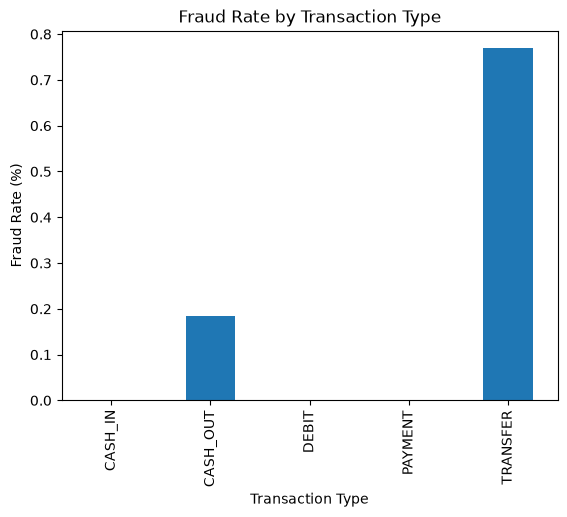

In [10]:
fraud_summary['fraud_rate'].plot(kind="bar")
plt.ylabel('Fraud Rate (%)')
plt.xlabel('Transaction Type')
plt.title('Fraud Rate by Transaction Type')
plt.show()

In [28]:
fraud_transactions = df.groupby('type')['isFraud'].sum()
legit_transactions = df.groupby('type')['isFraud'].count() - fraud_transactions

In [31]:
fraud_transactions, legit_transactions

(type
 CASH_IN        0
 CASH_OUT    4116
 DEBIT          0
 PAYMENT        0
 TRANSFER    4097
 Name: isFraud, dtype: int64,
 type
 CASH_IN     1399284
 CASH_OUT    2233384
 DEBIT         41432
 PAYMENT     2151495
 TRANSFER     528812
 Name: isFraud, dtype: int64)

In [32]:
amount_stats = df.groupby(['type', 'isFraud'])['amount'].agg(
    mean_transaction="mean",
    median_transaction="median",
    min_transactions="min",
    max_transactions="max"
)
amount_stats

mean_transaction  median_transaction  min_transactions  \
type     isFraud                                                           
CASH_IN  0            1.689202e+05          143427.710              0.04   
CASH_OUT 0            1.739172e+05          146946.560              0.01   
         1            1.455103e+06          435516.905              0.00   
DEBIT    0            5.483665e+03            3048.990              0.55   
PAYMENT  0            1.305760e+04            9482.190              0.02   
TRANSFER 0            9.062290e+05          486521.910              2.60   
         1            1.480892e+06          445705.760             63.80   

                  max_transactions  
type     isFraud                    
CASH_IN  0              1915267.90  
CASH_OUT 0              2847566.62  
         1             10000000.00  
DEBIT    0               569077.51  
PAYMENT  0               238637.98  
TRANSFER 0             92445516.64  
         1             10000000.00

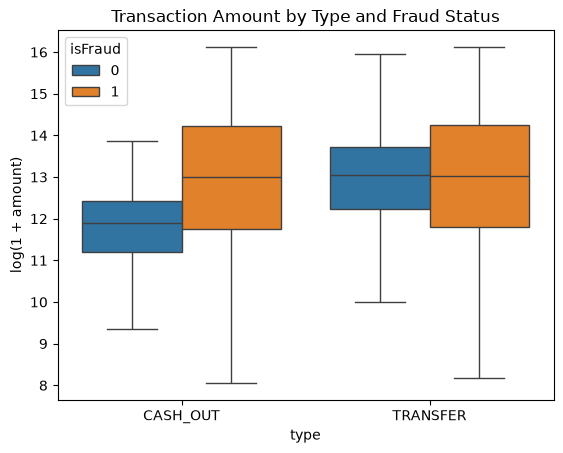

In [40]:
import seaborn as sns

plot_df = (
    df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
    .groupby(["type", "isFraud"], group_keys=False)
    .sample(n=3000, random_state=42)
    .copy()
)

plot_df["log_amount"] = np.log1p(plot_df["amount"])

sns.boxplot(
    data=plot_df,
    x="type",
    y="log_amount",
    hue="isFraud",
    showfliers=False
)

plt.title("Transaction Amount by Type and Fraud Status")
plt.ylabel("log(1 + amount)")
plt.show()

In [41]:
large_transfers = df[
    (df["type"] == "TRANSFER") &
    (df["amount"] > 500_000)
]

fraud_rate = large_transfers["isFraud"].mean() * 100

print(f"Fraud rate: {fraud_rate:.4f}%")

Fraud rate: 0.7431%


In [42]:
fraud_by_step = df.groupby("step")["isFraud"].agg(
    total_transactions="count",
    fraud_count="sum",
    fraud_rate="mean"
)

fraud_by_step["fraud_rate"] *= 100

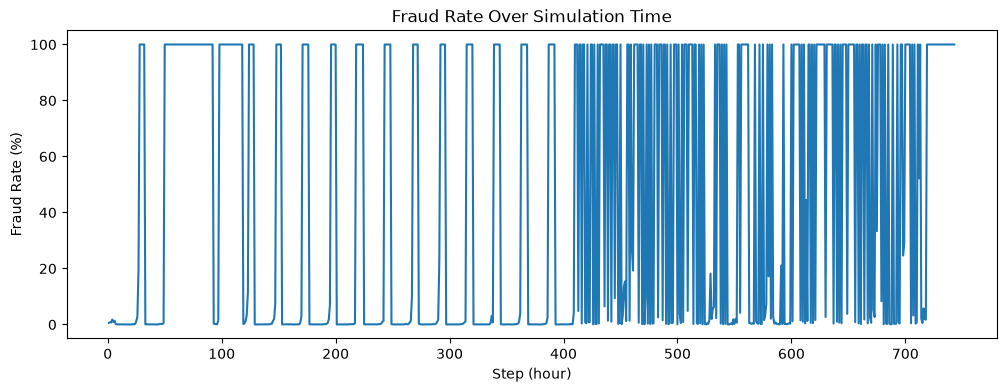

In [43]:
fraud_by_step["fraud_rate"].plot(
    figsize=(12, 4),
    title="Fraud Rate Over Simulation Time"
)

plt.xlabel("Step (hour)")
plt.ylabel("Fraud Rate (%)")
plt.show()

In [44]:
fraud_by_step[
    fraud_by_step["fraud_rate"] == 100
][["total_transactions", "fraud_count"]].head(15)

,total_transactions,fraud_count
step,,
28,4,4
29,4,4
30,8,8
31,12,12
32,12,12
50,6,6
51,14,14
52,8,8
53,10,10


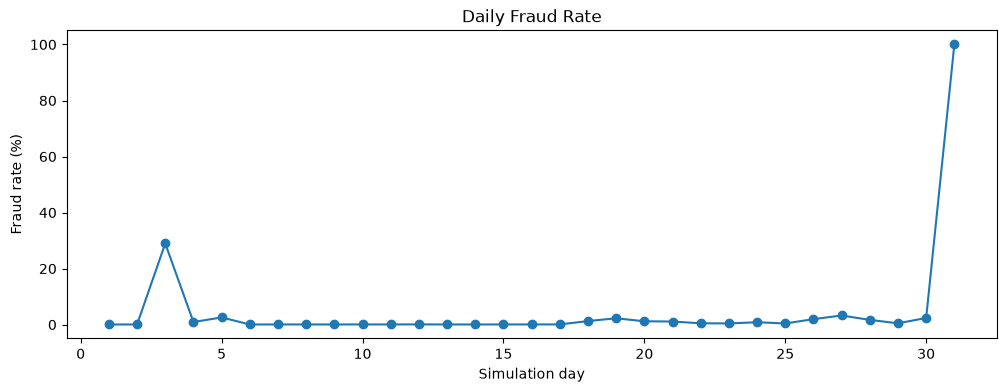

In [45]:
df["day"] = ((df["step"] - 1) // 24) + 1

fraud_by_day = df.groupby("day")["isFraud"].agg(
    total_transactions="count",
    fraud_count="sum",
    fraud_rate="mean"
)

fraud_by_day["fraud_rate"] *= 100

fraud_by_day["fraud_rate"].plot(
    figsize=(12, 4),
    marker="o"
)

plt.xlabel("Simulation day")
plt.ylabel("Fraud rate (%)")
plt.title("Daily Fraud Rate")
plt.show()